In [139]:
import pandas as pd # first uv add pandas
from pandas.api.types import CategoricalDtype
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### HELPERS

In [140]:
# Función para graficar
def plot_histograma(data, column, figsize=(6, 3), bins=15, kde=True, mvd=True, shade=True, snk=False):
    skewness = (data[column]).skew()
    kurtosis = (data[column]).kurt()
    media = (data[column]).mean()
    var = (data[column]).var()
    std = (data[column]).std()
    plt.figure(figsize=figsize)
    plt.grid(axis='y')
    sns.histplot(data[column], bins=bins, kde=kde)
    if snk:
        plt.figtext(0.7, 0.8, f'Asimetría: {skewness:.2f}', fontsize=10, color='blue')
        plt.figtext(0.715, 0.73, f'Curtosis: {kurtosis:.2f}', fontsize=10, color='blue')
        plt.axvline(media, color='red', linestyle='--', label='Media')
 

    # Sombreado
    if mvd and shade:
        plt.axvspan(media - std, media + std, alpha=0.1, color='orange', label='±1 Std')
        plt.axvline(media + std, color='orange', linestyle=':', label='+1 Std')
        plt.axvline(media - std, color='orange', linestyle=':', label='-1 Std')
        plt.figtext(0.15, 0.80, f'Media: {media:.2f}', fontsize=10, color='red')
        plt.figtext(0.15, 0.73, f'Var:   {var:.2f}',   fontsize=10, color='red')
        plt.figtext(0.15, 0.66, f'Std:   {std:.2f}',   fontsize=10, color='orange')

    

    plt.title(f'Variable: {column}')
    plt.xlabel(f'{column}')
    plt.ylabel('Frecuencia')
    plt.show()
    
    return

In [141]:
def cuartiles(variable):
    Q1 = variable.quantile(0.25)
    Q2 = variable.quantile(0.50)  # Percentile 5-0 - Equivalente a la mediana
    Q3 = variable.quantile(0.75)
    return Q1, Q2, Q3

In [142]:
def print_categorias(dataframe, columna):
    print(f"Cantidad de categorías que tiene la variable '{columna}': {dataframe[columna].nunique()}\n")
    print(f"Nombres de categorías presentes en la variable '{columna}': {dataframe[columna].unique()}\n")
    
    freq = dataframe[columna].value_counts()
    freq_rel = dataframe[columna].value_counts(normalize=True).mul(100).round(2)
    
    freq_tabla = pd.DataFrame({'Frecuencia absoluta': freq, 'Frecuencia relativa (%)': freq_rel})
    
    print(f"Frecuencias de cada categoría en la variable '{columna}':\n{freq_tabla}\n")

#### Descripción del dataset Pokémon

| Variable | Descripción | Ejemplo |
|---|---|---|
| `id` | Identificador numérico único del Pokémon (número de Pokédex). | `1` |
| `name` | Nombre del Pokémon (en minúsculas). | `bulbasaur` |
| `height_dm` | Altura del Pokémon, en decímetros. | `7` |
| `weight_hg` | Peso del Pokémon, en hectogramos. | `69` |
| `base_experience` | Experiencia base otorgada al derrotarlo; también indica qué tan avanzado o fuerte es. | `64.0` |
| `type_1` | Tipo primario (por ejemplo: grass, fire, water). | `grass` |
| `type_2` | Tipo secundario; vacío si el Pokémon tiene un solo tipo. | `poison` |
| `hp` | Puntos de salud base (Hit Points). | `45` |
| `attack` | Estadística base de ataque físico. | `49` |
| `defense` | Estadística base de defensa física. | `49` |
| `special_attack` | Estadística base de ataque especial. | `65` |
| `special_defense` | Estadística base de defensa especial. | `65` |
| `speed` | Estadística base de velocidad; determina quién actúa primero en combate. | `45` |
| `abilities` | Habilidades del Pokémon, separadas por comas dentro de un mismo campo de texto. | `overgrow, chlorophyll` |
| `generation` | Generación en la que fue introducido. | `generation-i` |
| `is_legendary` | Indica si es un Pokémon legendario (`True`/`False`). | `False` |
| `is_mythical` | Indica si es un Pokémon mítico (`True`/`False`). | `False` |
| `color` | Color principal del Pokémon según la Pokédex. | `green` |
| `shape` | Forma corporal según la Pokédex. | `quadruped` |
| `capture_rate` | Tasa de captura (0–255); valores más altos indican mayor facilidad de captura. | `45` |

In [143]:
# STEP 1 LOAD DATASET
df = pd.read_csv('./Dataset/pokemon_complete_stats.csv')
df.head()

,id,name,height_dm,weight_hg,base_experience,type_1,type_2,hp,attack,defense,special_attack,special_defense,speed,abilities,generation,is_legendary,is_mythical,color,shape,capture_rate
0,1,bulbasaur,7,69,64.0,grass,poison,45,49,49,65,65,45,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
1,2,ivysaur,10,130,142.0,grass,poison,60,62,63,80,80,60,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
2,3,venusaur,20,1000,236.0,grass,poison,80,82,83,100,100,80,"overgrow, chlorophyll",generation-i,False,False,green,quadruped,45
3,4,charmander,6,85,62.0,fire,NaN,39,52,43,60,50,65,"blaze, solar-power",generation-i,False,False,red,upright,45
4,5,charmeleon,11,190,142.0,fire,NaN,58,64,58,80,65,80,"blaze, solar-power",generation-i,False,False,red,upright,45


In [144]:
#STEP 2 Basic explore
print(f"Dimensiones del dataset: {df.shape}")


Dimensiones del dataset: (1351, 20)


In [145]:
df.columns

Index(['id', 'name', 'height_dm', 'weight_hg', 'base_experience', 'type_1',
       'type_2', 'hp', 'attack', 'defense', 'special_attack',
       'special_defense', 'speed', 'abilities', 'generation', 'is_legendary',
       'is_mythical', 'color', 'shape', 'capture_rate'],
      dtype='str')

In [146]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1351 non-null   int64  
 1   name             1351 non-null   str    
 2   height_dm        1351 non-null   int64  
 3   weight_hg        1351 non-null   int64  
 4   base_experience  1302 non-null   float64
 5   type_1           1351 non-null   str    
 6   type_2           765 non-null    str    
 7   hp               1351 non-null   int64  
 8   attack           1351 non-null   int64  
 9   defense          1351 non-null   int64  
 10  special_attack   1351 non-null   int64  
 11  special_defense  1351 non-null   int64  
 12  speed            1351 non-null   int64  
 13  abilities        1337 non-null   str    
 14  generation       1351 non-null   str    
 15  is_legendary     1351 non-null   bool   
 16  is_mythical      1351 non-null   bool   
 17  color            1351 non

**Identificacion y ajuste de tipos de variables**

In [147]:
pokemon_numericas = ['height_dm','weight_hg', 'base_experience','hp', 'attack','defense','special_attack','special_defense', 'speed','capture_rate']
pokemon_cat_nom = ['type_1','type_2','abilities','is_legendary','is_mythical','color','shape']
pokemon_cat_ord = { 
    'generation': CategoricalDtype( 
        categories = ['generation-i',
                      'generation-ii',
                      'generation-iii',
                      'generation-iv',
                      'generation-v',
                      'generation-vi',
                      'generation-vii',
                      'generation-viii',
                      'generation-ix']
        , ordered = True )
}

dtype_map = { col: 'float64' for col in pokemon_numericas } # Mapping para variables numéricas
dtype_map.update( { col: 'category' for col in pokemon_cat_nom } ) # Mapping para categoricas nominales
dtype_map.update(pokemon_cat_ord) # Mapping para las categoricas ordinales

df = df.astype(dtype_map) # Aplicamos mapping al dataFrame


---
---
## Estadística descriptiva
---
---

### 1. Exploración de VARIABLES NUMÉRICAS

#### 1.1. Medidas de tendencia central: media, mediana y moda

In [148]:
tendencia_central = pd.DataFrame({
    'Media': df[pokemon_numericas].mean(),
    'Mediana': df[pokemon_numericas].median(),
    'Moda': df[pokemon_numericas].mode().iloc[0] # iloc = integer location
})
tendencia_central.round(2)

,Media,Mediana,Moda
height_dm,20.44,11.0,3.0
weight_hg,991.06,326.0,10000.0
base_experience,161.94,165.0,270.0
hp,71.67,70.0,60.0
attack,82.76,80.0,100.0
defense,76.19,70.0,70.0
special_attack,75.42,69.0,50.0
special_defense,74.12,70.0,50.0
speed,72.00,70.0,60.0
capture_rate,89.11,55.0,45.0


#### 1.2. Histogramas

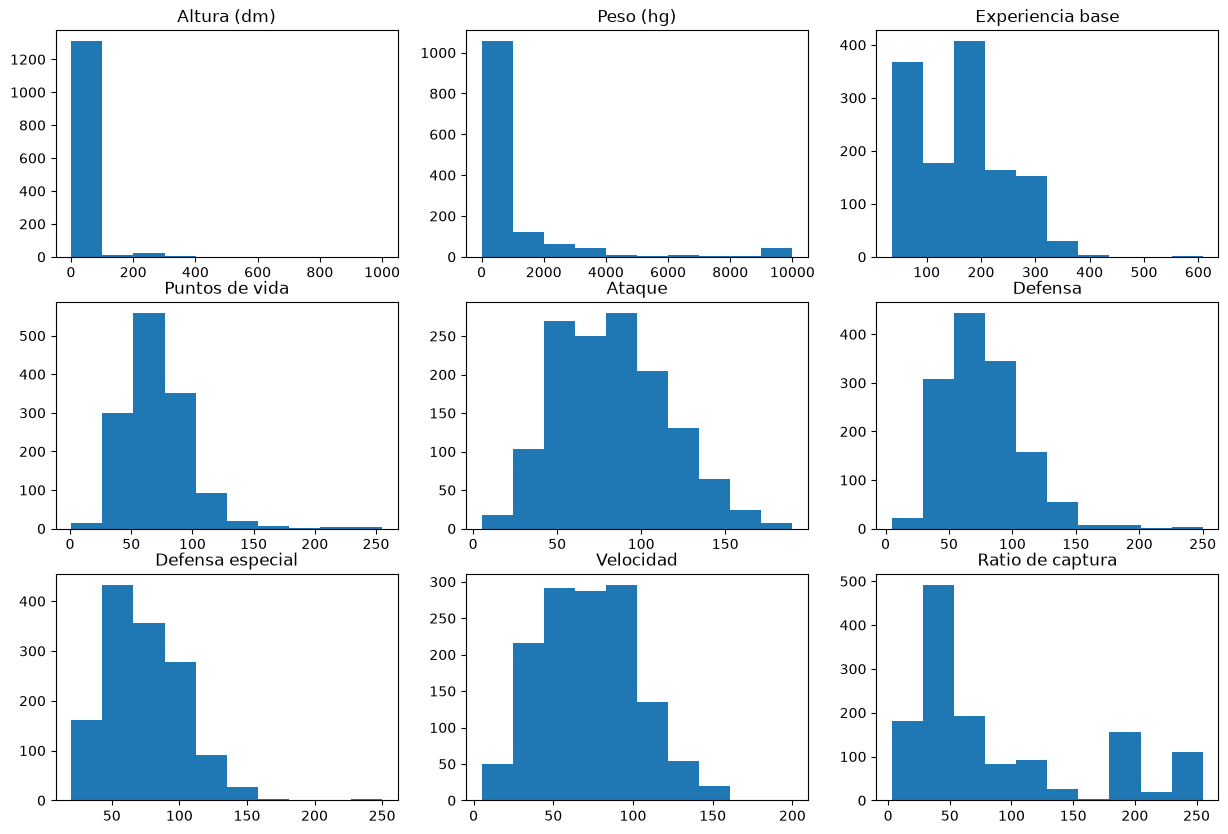

In [149]:
fig, ax = plt.subplots(3, 3, figsize=(15, 10))

ax[0,0].hist(df['height_dm'])
ax[0,0].set_title('Altura (dm)')

ax[0,1].hist(df['weight_hg'])
ax[0,1].set_title('Peso (hg)')

ax[0,2].hist(df['base_experience']) 
ax[0,2].set_title('Experiencia base')

ax[1,0].hist(df['hp']) 
ax[1,0].set_title('Puntos de vida')

ax[1,1].hist(df['attack'])
ax[1,1].set_title('Ataque')

ax[1,2].hist(df['defense'])
ax[1,2].set_title('Defensa')

ax[2,0].hist(df['special_defense'])
ax[2,0].set_title('Defensa especial')

ax[2,1].hist(df['speed'])
ax[2,1].set_title('Velocidad')

ax[2,2].hist(df['capture_rate'])
ax[2,2].set_title('Ratio de captura')
 

plt.show()

#### KDE (Kernel Density Estimation)

<Axes: xlabel='capture_rate', ylabel='Density'>

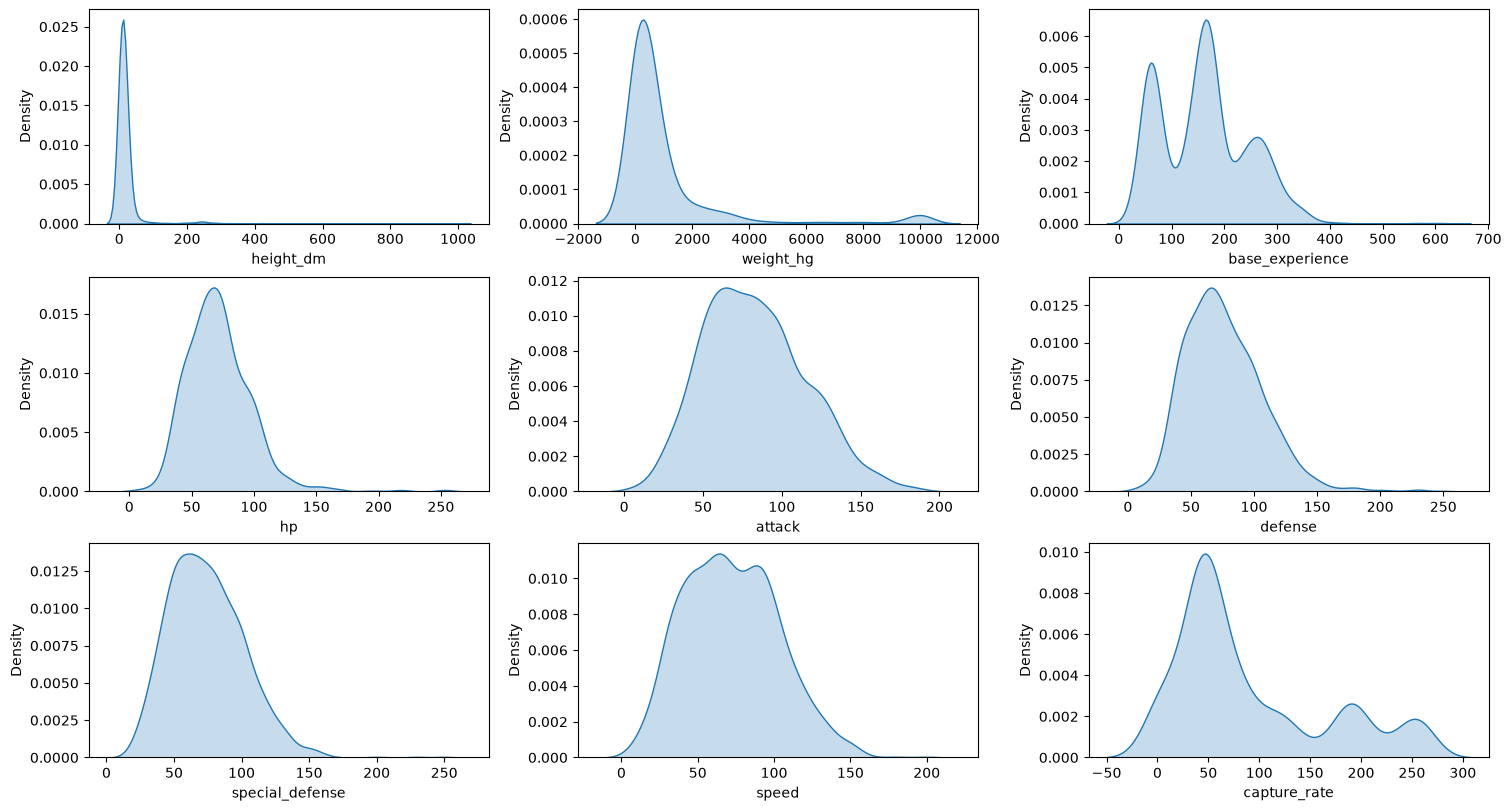

In [150]:
fig, axes = plt.subplots(3, 3, figsize=(15, 8), layout='constrained')

sns.kdeplot(data=df, x='height_dm', fill=True, ax=axes[0,0])
sns.kdeplot(data=df, x='weight_hg', fill=True, ax=axes[0,1])
sns.kdeplot(data=df, x='base_experience', fill=True, ax=axes[0,2])
sns.kdeplot(data=df, x='hp', fill=True, ax=axes[1,0])
sns.kdeplot(data=df, x='attack', fill=True, ax=axes[1,1])
sns.kdeplot(data=df, x='defense', fill=True, ax=axes[1,2])
sns.kdeplot(data=df, x='special_defense', fill=True, ax=axes[2,0])
sns.kdeplot(data=df, x='speed', fill=True, ax=axes[2,1])
sns.kdeplot(data=df, x='capture_rate', fill=True, ax=axes[2,2])





### 1.3. Medidas de dispersión

In [151]:
dispersion = pd.DataFrame({
    'Media': df[pokemon_numericas].mean(),
    'Var': df[pokemon_numericas].var(),
    'STD': df[pokemon_numericas].std()
})
dispersion.round(2)

,Media,Var,STD
height_dm,20.44,2834.33,53.24
weight_hg,991.06,3814661.37,1953.12
base_experience,161.94,6811.62,82.53
hp,71.67,719.72,26.83
attack,82.76,1046.65,32.35
defense,76.19,943.28,30.71
special_attack,75.42,1157.79,34.03
special_defense,74.12,772.89,27.80
speed,72.00,938.93,30.64
capture_rate,89.11,5534.28,74.39


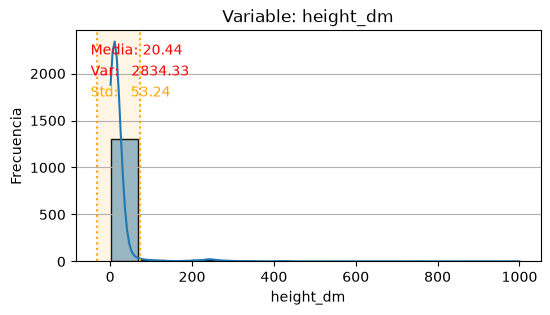

In [152]:
plot_histograma(df, 'height_dm')

Casi la totalidad de los pokemons se concentra en valores bajos y existe un pequeño grupo de valores extermos que se extiende hasta los 1000 dm

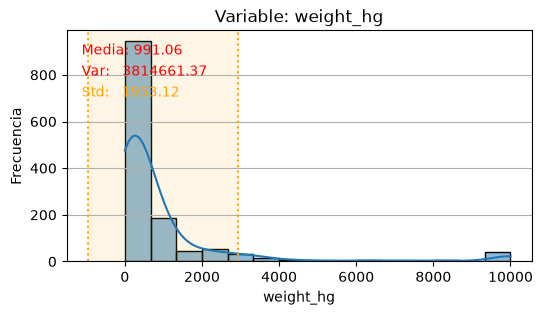

In [153]:
plot_histograma(df, 'weight_hg')

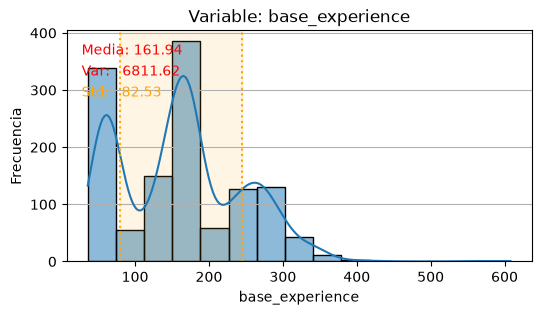

In [154]:
plot_histograma(df, 'base_experience')

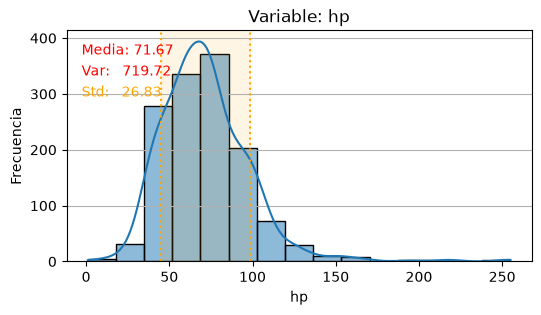

In [155]:
plot_histograma(df, 'hp')

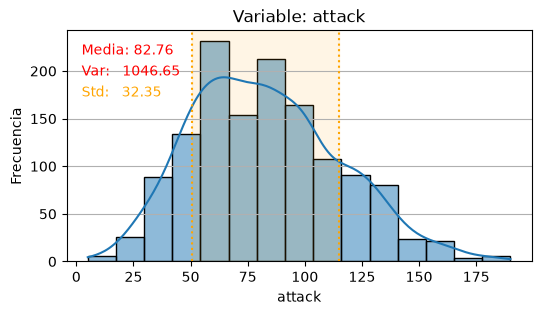

In [156]:
plot_histograma(df, 'attack')

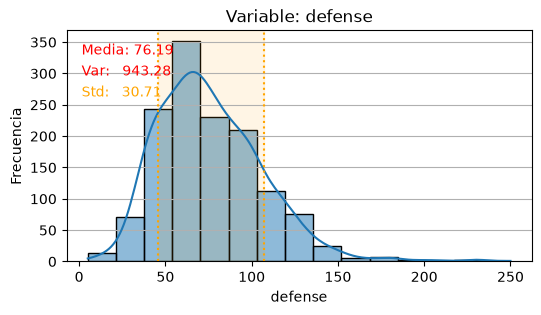

In [157]:
plot_histograma(df, 'defense')

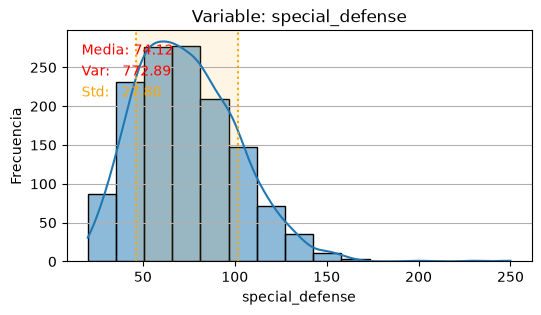

In [158]:
plot_histograma(df, 'special_defense')

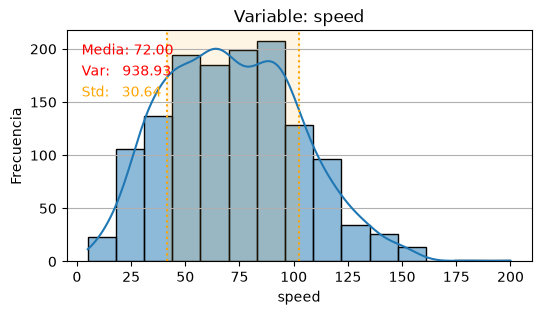

In [159]:
plot_histograma(df, 'speed')

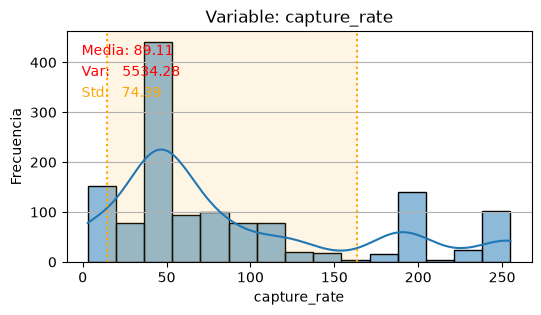

In [160]:
plot_histograma(df, 'capture_rate')

### 1.4. Cuartiles y IQR

In [161]:
cuartiles_df = pd.DataFrame(
    {col: cuartiles(df[col]) for col in pokemon_numericas},
    index=['Q1 (25%)', 'Q2 (Mediana)', 'Q3 (75%)']
).T
cuartiles_df['IQR'] = cuartiles_df['Q3 (75%)'] - cuartiles_df['Q1 (25%)']
cuartiles_df.round(2)


,Q1 (25%),Q2 (Mediana),Q3 (75%),IQR
height_dm,6.0,11.0,17.0,11.0
weight_hg,94.5,326.0,853.5,759.0
base_experience,71.0,165.0,222.5,151.5
hp,55.0,70.0,85.0,30.0
attack,60.0,80.0,102.5,42.5
defense,55.0,70.0,95.0,40.0
special_attack,50.0,69.0,97.0,47.0
special_defense,54.0,70.0,90.0,36.0
speed,49.0,70.0,95.0,46.0
capture_rate,45.0,55.0,120.0,75.0


---
### 2. Exploración de VARIABLES CATEGÓRICAS

#### 2.1. Frecuencias y categorías

In [162]:
for col in pokemon_cat_nom:
    print_categorias(df, col)
    print("-" * 50)

Cantidad de categorías que tiene la variable 'type_1': 18

Nombres de categorías presentes en la variable 'type_1': ['grass', 'fire', 'water', 'bug', 'normal', ..., 'ice', 'dragon', 'dark', 'steel', 'flying']
Length: 18
Categories (18, str): ['bug', 'dark', 'dragon', 'electric', ..., 'psychic', 'rock', 'steel', 'water']

Frecuencias de cada categoría en la variable 'type_1':
          Frecuencia absoluta  Frecuencia relativa (%)
type_1                                                
water                     160                    11.84
normal                    139                    10.29
grass                     122                     9.03
electric                  100                     7.40
bug                        95                     7.03
psychic                    86                     6.37
fire                       84                     6.22
rock                       83                     6.14
dark                       63                     4.66
fighting         

#### 2.2. Descripción de categóricas con la función $\texttt{describe}$

In [163]:
df.describe(include='category')

,type_1,type_2,abilities,generation,is_legendary,is_mythical,color,shape
count,1351,765,1337,1351,1351,1351,1351,1351
unique,18,18,719,9,2,2,10,14
top,water,flying,levitate,generation-i,False,False,blue,upright
freq,160,141,38,238,1231,1313,216,284


---
### 3. Relaciones entre variables

#### 3.1. Numérica-numérica

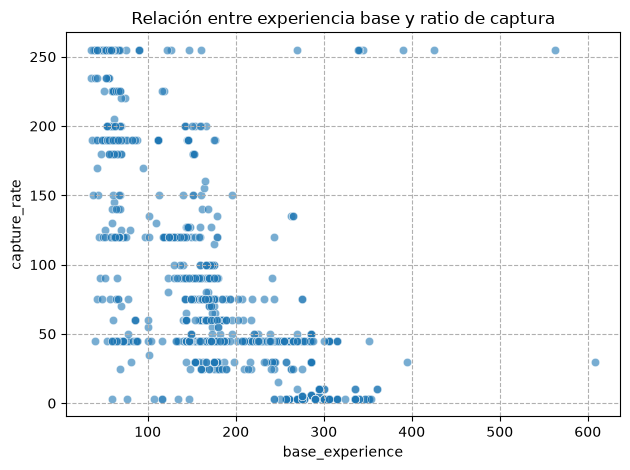

In [164]:
sns.scatterplot(data=df, x='base_experience', y='capture_rate', alpha=0.6)
plt.grid(ls='--')
plt.title('Relación entre experiencia base y ratio de captura')
plt.tight_layout()
plt.show()

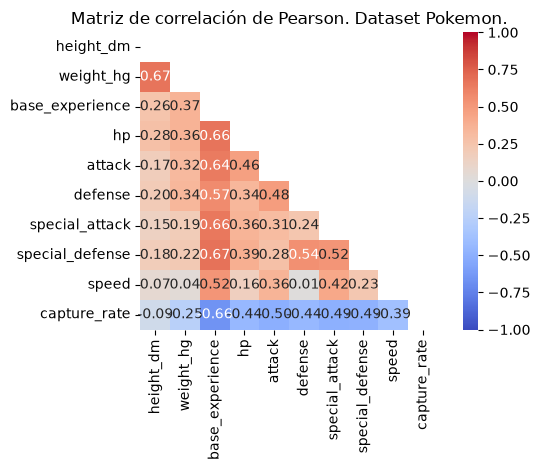

In [165]:
corr_matrix = df[pokemon_numericas].corr()

# Creamos una máscara para ocultar la mitad superior de la matriz
mascara = np.triu(np.ones_like(corr_matrix, dtype=bool)) 

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, mask=mascara) # Se filtra aplicando una máscara
plt.title('Matriz de correlación de Pearson. Dataset Pokemon.')
plt.tight_layout()
plt.show()

#### 3.2. Categórica-categórica

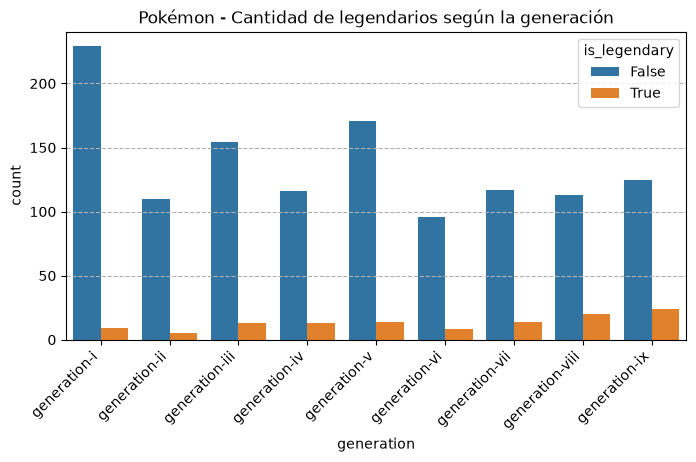

In [166]:
orden = ['generation-i', 'generation-ii', 'generation-iii', 'generation-iv',
         'generation-v', 'generation-vi', 'generation-vii', 'generation-viii',
         'generation-ix']

plt.figure(figsize=(8, 4))
sns.countplot(x='generation', hue='is_legendary', data=df, order=orden)
plt.grid(ls='--', axis='y')
plt.title('Pokémon - Cantidad de legendarios según la generación')
plt.xticks(rotation=45, ha='right')
plt.show()

#### 3.3. Numéricas-categóricas

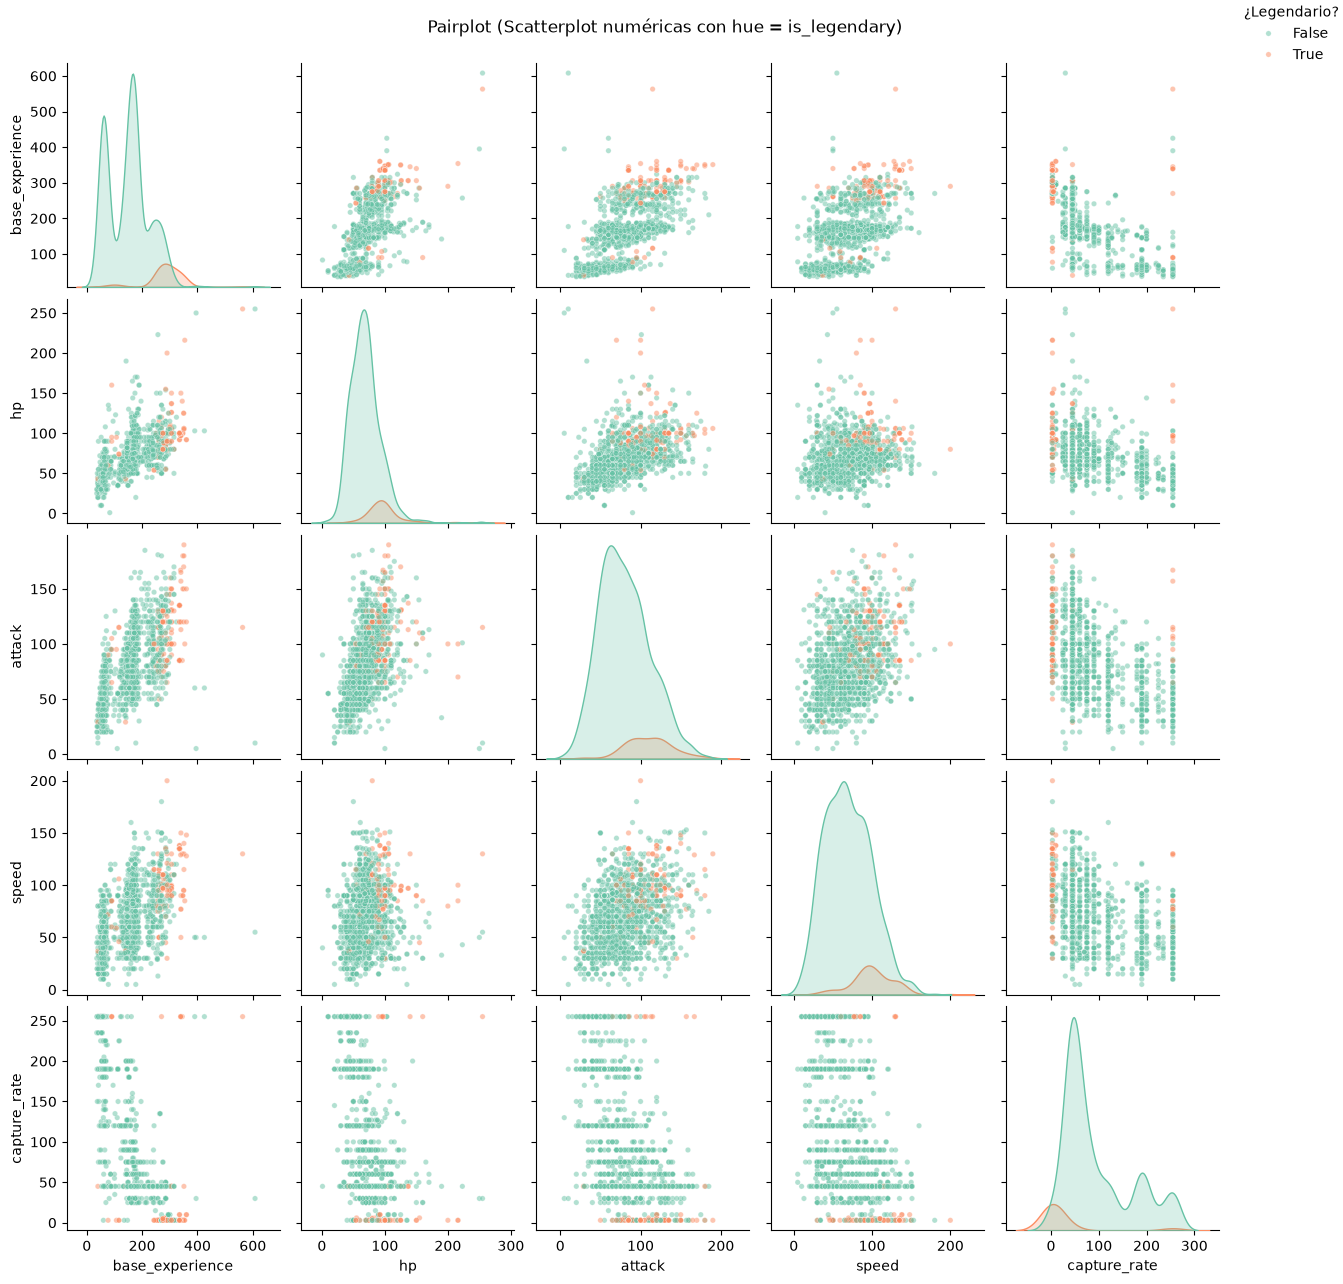

In [167]:
grafico = sns.pairplot(
    data=df,
    vars=['base_experience', 'hp', 'attack', 'speed', 'capture_rate'],
    hue='is_legendary',
    palette='Set2',
    plot_kws={'alpha': 0.5, 's': 15}
)
grafico.figure.suptitle('Pairplot (Scatterplot numéricas con hue = is_legendary)', y=1.02)

grafico.legend.set_bbox_to_anchor((1, 1))
grafico.legend.set_title('¿Legendario?')

plt.show()